# DEEP LEARNING - AIR QUALITY ROBUSTNESS ANALYSIS

## Research Question

**Do deep learning models remain reliable during extreme pollution episodes, or does their prediction performance degrade when AQI becomes severe?**

### Objective

This notebook evaluates the robustness of four deep learning architectures:

1. Multi-Layer Perceptron (MLP)
2. Recurrent Neural Network (RNN)
3. Gated Recurrent Unit (GRU)
4. Transformer

The models are evaluated for **US_AQI prediction** under:

- Overall air-quality conditions
- Extreme pollution conditions (`US_AQI >= 201`)

The main objective is to determine whether predictive performance degrades during extreme pollution episodes.

### Evaluation Metrics

The models will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [23]:
# ============================================================
#  IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Dense,
    SimpleRNN,
    GRU,
    MultiHeadAttention,
    LayerNormalization,
    Dropout,
    GlobalAveragePooling1D
)

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)


# ------------------------------------------------------------
# Version Check
# ------------------------------------------------------------

print("=" * 60)
print(" IMPORT LIBRARIES")
print("=" * 60)

print("\nTensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

print("\nAll libraries imported successfully.")

 IMPORT LIBRARIES

TensorFlow Version : 2.21.0
NumPy Version      : 2.4.3
Pandas Version     : 2.3.3

All libraries imported successfully.


In [24]:
# ============================================================
#  LOAD DATASET
# ============================================================

DATASET_PATH = (
    "../dataset/INDIA_AQI_COMPLETE_20251126.csv"
)

# Load dataset
df = pd.read_csv(DATASET_PATH)

print("=" * 60)
print(" DATASET LOADED")
print("=" * 60)

print("\nDataset Shape :", df.shape)

print(
    "\nDataset loaded successfully."
)

 DATASET LOADED

Dataset Shape : (842160, 71)

Dataset loaded successfully.


In [25]:
# ============================================================
#  DATASET VERIFICATION
# ============================================================

print("=" * 60)
print(" DATASET VERIFICATION")
print("=" * 60)

# 1. Dataset dimensions
print("\n1. Dataset Shape:")
print(df.shape)

# 2. Preview
print("\n2. First 5 Rows:")
display(df.head())

# 3. Required columns
required_columns = [
    "Datetime",
    "City",
    "US_AQI"
]

print("\n3. Required Column Verification:")

for column in required_columns:
    if column in df.columns:
        print(f"{column}: FOUND")
    else:
        print(f"{column}: MISSING")

# 4. Dataset data types
print("\n4. Datetime Data Type:")
print(df["Datetime"].dtype if "Datetime" in df.columns else "Missing")

print("\n5. Target Data Type:")
print(df["US_AQI"].dtype if "US_AQI" in df.columns else "Missing")

# 5. City count
if "City" in df.columns:
    print("\n6. Unique Cities:")
    print(df["City"].nunique())

# 6. Target missing values
if "US_AQI" in df.columns:
    print("\n7. Missing US_AQI Values:")
    print(df["US_AQI"].isna().sum())

# 7. Verification result
if all(column in df.columns for column in required_columns):
    print("\nDATASET VERIFICATION PASSED.")
else:
    raise ValueError(
        "Required columns are missing. Check the dataset."
    )

 DATASET VERIFICATION

1. Dataset Shape:
(842160, 71)

2. First 5 Rows:


,City,State,Latitude,Longitude,Datetime,Year,Month,Day,Hour,Day_of_Week,...,US_AQI_CO,EU_AQI,EU_AQI_PM25,EU_AQI_PM10,AQI_Category,PM25_Category_India,Temp_Inversion,Inversion_Strength_C,Festival_Period,Crop_Burning_Season
0,Agartala,Tripura,23.8315,91.2868,2022-08-05 00:00:00,2022,8,5,0,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
1,Agartala,Tripura,23.8315,91.2868,2022-08-05 01:00:00,2022,8,5,1,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
2,Agartala,Tripura,23.8315,91.2868,2022-08-05 02:00:00,2022,8,5,2,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
3,Agartala,Tripura,23.8315,91.2868,2022-08-05 03:00:00,2022,8,5,3,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0
4,Agartala,Tripura,23.8315,91.2868,2022-08-05 04:00:00,2022,8,5,4,4,...,2,NaN,NaN,NaN,NaN,Good,0,NaN,0,0



3. Required Column Verification:
Datetime: FOUND
City: FOUND
US_AQI: FOUND

4. Datetime Data Type:
object

5. Target Data Type:
float64

6. Unique Cities:
29

7. Missing US_AQI Values:
145

DATASET VERIFICATION PASSED.


In [26]:

# ============================================================
#  TARGET & FEATURE DEFINITION
# ============================================================

TARGET = "US_AQI"

SEQUENCE_FEATURES = [
    "PM2_5_ugm3",
    "PM10_ugm3",
    "CO_ugm3",
    "NO2_ugm3",
    "SO2_ugm3",
    "O3_ugm3",
    "Dust_ugm3",
    "AOD",
    "Temp_2m_C",
    "Humidity_Percent",
    "Wind_Speed_10m_kmh",
    "Pressure_MSL_hPa",
    "Precipitation_mm",
    "Solar_Radiation_Wm2"
]

EXTREME_AQI_THRESHOLD = 201

print("=" * 60)
print(" TARGET & FEATURE DEFINITION")
print("=" * 60)

print("\nTarget Variable:", TARGET)
print("Number of Input Features:", len(SEQUENCE_FEATURES))

print("\nInput Features:")
for i, feature in enumerate(SEQUENCE_FEATURES, start=1):
    print(f"{i:02d}. {feature}")

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)

# Verify that all selected columns exist
missing_columns = [
    column
    for column in [TARGET, "Datetime", "City"] + SEQUENCE_FEATURES
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

print("\nAll required columns are available.")
print(" COMPLETED SUCCESSFULLY.")


 TARGET & FEATURE DEFINITION

Target Variable: US_AQI
Number of Input Features: 14

Input Features:
01. PM2_5_ugm3
02. PM10_ugm3
03. CO_ugm3
04. NO2_ugm3
05. SO2_ugm3
06. O3_ugm3
07. Dust_ugm3
08. AOD
09. Temp_2m_C
10. Humidity_Percent
11. Wind_Speed_10m_kmh
12. Pressure_MSL_hPa
13. Precipitation_mm
14. Solar_Radiation_Wm2

Extreme AQI Threshold: 201

All required columns are available.
 COMPLETED SUCCESSFULLY.



##  DATA LEAKAGE PREVENTION

Data leakage occurs when information that would not be available at prediction time influences model training or evaluation.

To reduce data leakage in this experiment:

1. `US_AQI` will be used only as the prediction target.
2. `City` and `Datetime` will be used to organize the time-series data, not as direct input features.
3. The selected input features will exclude `US_AQI` and other direct target-derived AQI columns.
4. Training and testing will follow a chronological strategy.
5. Feature scaling parameters will be learned from training-period data only.
6. Test-period observations will not be used to fit the models or preprocessing steps.

These precautions help provide a more realistic evaluation of future AQI prediction performance.


In [27]:

# ============================================================
#  MISSING TARGET HANDLING
# ============================================================

print("=" * 60)
print(" MISSING TARGET HANDLING")
print("=" * 60)

# Check missing target values
missing_target_count = df[TARGET].isna().sum()

print("\nTotal Dataset Rows :", len(df))
print("Missing US_AQI     :", missing_target_count)
print("Available Targets  :", df[TARGET].notna().sum())

# Check whether selected input features contain missing values
missing_feature_counts = df[SEQUENCE_FEATURES].isna().sum()

print("\nMissing Values in Input Features:")
print(missing_feature_counts[missing_feature_counts > 0])

# Preserve the original dataset.
# Rows with missing targets will not be used as prediction targets.
# They may still be useful as historical input observations.

df_model = df.copy()

print("\nOriginal dataset preserved in variable: df")
print("Working dataset created in variable: df_model")

print("\nNo rows have been deleted in this step.")
print("Missing-target observations will be excluded")
print("when prediction sequences are constructed.")

print("\n COMPLETED SUCCESSFULLY.")


 MISSING TARGET HANDLING

Total Dataset Rows : 842160
Missing US_AQI     : 145
Available Targets  : 842015

Missing Values in Input Features:
Series([], dtype: int64)

Original dataset preserved in variable: df
Working dataset created in variable: df_model

No rows have been deleted in this step.
Missing-target observations will be excluded
when prediction sequences are constructed.

 COMPLETED SUCCESSFULLY.


In [28]:

# ============================================================
#  CATEGORICAL ENCODING & DATETIME PREPARATION
# ============================================================

print("=" * 60)
print(" CATEGORICAL ENCODING & DATETIME PREPARATION")
print("=" * 60)

# 1. Convert Datetime to pandas datetime format
df_model["Datetime"] = pd.to_datetime(
    df_model["Datetime"],
    errors="raise"
)

# 2. Verify that all selected input features are numeric
non_numeric_features = [
    feature
    for feature in SEQUENCE_FEATURES
    if not pd.api.types.is_numeric_dtype(df_model[feature])
]

if non_numeric_features:
    raise TypeError(
        f"Non-numeric input features found: {non_numeric_features}"
    )

# 3. Keep City as a grouping identifier, not a model input
print("\nCity Encoding:")
print("City will be used for grouping, not as a model feature.")
print("No categorical encoding is required for the selected inputs.")

# 4. Sort observations chronologically within each city
df_model = df_model.sort_values(
    ["City", "Datetime"]
).reset_index(drop=True)

# 5. Check duplicate city-timestamp combinations
duplicate_count = df_model.duplicated(
    subset=["City", "Datetime"]
).sum()

# 6. Check time gaps between consecutive observations
time_differences = (
    df_model.groupby("City")["Datetime"].diff()
)

gap_count = (
    time_differences.notna()
    & (time_differences != pd.Timedelta(hours=1))
).sum()

print("\nDatetime Data Type:", df_model["Datetime"].dtype)
print("Number of Cities:", df_model["City"].nunique())
print("Duplicate City-Timestamp Rows:", duplicate_count)
print("Non-hourly Consecutive Time Differences:", gap_count)

print("\nSorted Dataset Shape:", df_model.shape)

if duplicate_count > 0:
    print("\nWARNING: Duplicate city-timestamp records require investigation.")
else:
    print("\nNo duplicate city-timestamp records found.")

if gap_count > 0:
    print("WARNING: Time gaps or irregular intervals were detected.")
    print("Sequence construction must account for these intervals.")
else:
    print("All consecutive observations are hourly within each city.")

print("\ COMPLETED.")


 CATEGORICAL ENCODING & DATETIME PREPARATION

City Encoding:
City will be used for grouping, not as a model feature.
No categorical encoding is required for the selected inputs.

Datetime Data Type: datetime64[ns]
Number of Cities: 29
Duplicate City-Timestamp Rows: 0
Non-hourly Consecutive Time Differences: 0

Sorted Dataset Shape: (842160, 71)

No duplicate city-timestamp records found.
All consecutive observations are hourly within each city.
\ COMPLETED.



##  CHRONOLOGICAL TRAIN-TEST SPLIT

A chronological evaluation strategy will be used for this time-series forecasting experiment.

- Training period: the earlier 80% of the timeline.
- Testing period: the later 20% of the timeline.
- The temporal cutoff will be based on timestamps rather than random row selection.
- The same temporal cutoff will be applied consistently across all cities.
- Test-period observations will remain separate from model fitting and preprocessing.

This approach evaluates how well the models generalize to later observations.


In [29]:

# ============================================================
#  DEFINE CHRONOLOGICAL TRAIN-TEST CUTOFF
# ============================================================

print("=" * 60)
print(" CHRONOLOGICAL TRAIN-TEST CUTOFF")
print("=" * 60)

# Sort unique timestamps across the complete dataset
unique_timestamps = np.sort(
    df_model["Datetime"].unique()
)

# Use the first 80% of timestamps for training
split_index = int(len(unique_timestamps) * 0.80)

# Ensure both periods contain timestamps
if split_index <= 0 or split_index >= len(unique_timestamps):
    raise ValueError("Invalid chronological split index.")

TRAIN_END_TIME = pd.Timestamp(
    unique_timestamps[split_index - 1]
)

TEST_START_TIME = pd.Timestamp(
    unique_timestamps[split_index]
)

# Assign rows according to timestamp
train_mask = df_model["Datetime"] <= TRAIN_END_TIME
test_mask = df_model["Datetime"] >= TEST_START_TIME

train_rows = df_model.loc[train_mask]
test_rows = df_model.loc[test_mask]

print("\nTotal Unique Timestamps:", len(unique_timestamps))
print("Training Cutoff:", TRAIN_END_TIME)
print("Testing Starts :", TEST_START_TIME)

print("\nTraining Rows:", len(train_rows))
print("Testing Rows :", len(test_rows))

print("\nTraining Period:")
print(train_rows["Datetime"].min(), "to", train_rows["Datetime"].max())

print("\nTesting Period:")
print(test_rows["Datetime"].min(), "to", test_rows["Datetime"].max())

print("\nTraining Percentage:", round(len(train_rows) / len(df_model) * 100, 2), "%")
print("Testing Percentage :", round(len(test_rows) / len(df_model) * 100, 2), "%")

# Verify chronological separation
assert train_rows["Datetime"].max() < test_rows["Datetime"].min()

print("\nChronological separation verified.")
print(" COMPLETED SUCCESSFULLY.")


 CHRONOLOGICAL TRAIN-TEST CUTOFF

Total Unique Timestamps: 29040
Training Cutoff: 2025-03-29 23:00:00
Testing Starts : 2025-03-30 00:00:00

Training Rows: 673728
Testing Rows : 168432

Training Period:
2022-08-05 00:00:00 to 2025-03-29 23:00:00

Testing Period:
2025-03-30 00:00:00 to 2025-11-26 23:00:00

Training Percentage: 80.0 %
Testing Percentage : 20.0 %

Chronological separation verified.
 COMPLETED SUCCESSFULLY.


In [30]:

# ============================================================
#  LEAKAGE-SAFE FEATURE SCALING
# ============================================================

print("=" * 60)
print(" LEAKAGE-SAFE FEATURE SCALING")
print("=" * 60)

# Create a dedicated scaler
feature_scaler = StandardScaler()

# Fit the scaler using training-period rows ONLY
training_feature_mask = (
    df_model["Datetime"] <= TRAIN_END_TIME
)

feature_scaler.fit(
    df_model.loc[training_feature_mask, SEQUENCE_FEATURES]
)

# Transform features for both training and testing periods
# Test data is transformed, but never used to fit the scaler.
df_scaled = df_model.copy()

df_scaled.loc[:, SEQUENCE_FEATURES] = feature_scaler.transform(
    df_model[SEQUENCE_FEATURES]
)

print("\nTraining cutoff:", TRAIN_END_TIME)
print("Training rows used to fit scaler:", training_feature_mask.sum())
print("Test rows used to fit scaler: 0")

print("\nScaled Dataset Shape:", df_scaled.shape)

print("\nExample: Original Feature Values")
display(df_model[SEQUENCE_FEATURES].head(3))

print("\nExample: Scaled Feature Values")
display(df_scaled[SEQUENCE_FEATURES].head(3))

# Verify that scaling parameters were fitted only on training data
assert feature_scaler.n_samples_seen_ == training_feature_mask.sum()

# Verify no missing values were introduced
assert df_scaled[SEQUENCE_FEATURES].isna().sum().sum() == 0

print("\nScaler fitted exclusively on training-period features.")
print("No missing values introduced by scaling.")
print(" COMPLETED SUCCESSFULLY.")


 LEAKAGE-SAFE FEATURE SCALING

Training cutoff: 2025-03-29 23:00:00
Training rows used to fit scaler: 673728
Test rows used to fit scaler: 0

Scaled Dataset Shape: (842160, 71)

Example: Original Feature Values


,PM2_5_ugm3,PM10_ugm3,CO_ugm3,NO2_ugm3,SO2_ugm3,O3_ugm3,Dust_ugm3,AOD,Temp_2m_C,Humidity_Percent,Wind_Speed_10m_kmh,Pressure_MSL_hPa,Precipitation_mm,Solar_Radiation_Wm2
0,14.8,21.5,197.0,21.8,2.7,32.0,0.0,0.14,26.7,91,5.4,1004.4,0.0,0.0
1,15.7,22.8,196.0,18.5,3.0,33.0,0.0,0.14,26.4,93,4.5,1003.9,0.0,0.0
2,16.3,23.5,196.0,15.1,3.3,34.0,0.0,0.15,26.1,95,3.8,1003.5,0.0,0.0



Example: Scaled Feature Values


,PM2_5_ugm3,PM10_ugm3,CO_ugm3,NO2_ugm3,SO2_ugm3,O3_ugm3,Dust_ugm3,AOD,Temp_2m_C,Humidity_Percent,Wind_Speed_10m_kmh,Pressure_MSL_hPa,Precipitation_mm,Solar_Radiation_Wm2
0,-0.666509,-0.542575,-0.581880,0.226499,-0.539992,-1.037706,-0.17887,-1.027739,0.508451,0.952197,-0.552519,-1.020244,-0.204678,-0.735772
1,-0.637986,-0.522015,-0.584028,0.076992,-0.526606,-1.016191,-0.17887,-1.027739,0.465922,1.045631,-0.728968,-1.108979,-0.204678,-0.735772
2,-0.618970,-0.510943,-0.584028,-0.077045,-0.513220,-0.994676,-0.17887,-0.995847,0.423392,1.139064,-0.866206,-1.179967,-0.204678,-0.735772



Scaler fitted exclusively on training-period features.
No missing values introduced by scaling.
 COMPLETED SUCCESSFULLY.


In [31]:

# ============================================================
#  TIME-SERIES SEQUENCE CREATION
# ============================================================

LOOKBACK = 24

X_sequences = []
y_sequences = []
sequence_cities = []
sequence_target_times = []

for city, city_df in df_scaled.groupby("City", sort=False):

    city_df = city_df.sort_values("Datetime").reset_index(drop=True)

    # Keep the original, unscaled AQI target
    original_city_df = df_model[
        df_model["City"] == city
    ].sort_values("Datetime").reset_index(drop=True)

    # Confirm feature and target rows remain aligned
    assert np.array_equal(
        city_df["Datetime"].to_numpy(),
        original_city_df["Datetime"].to_numpy()
    )

    feature_values = city_df[SEQUENCE_FEATURES].to_numpy(
        dtype=np.float32
    )

    target_values = original_city_df[TARGET].to_numpy(
        dtype=np.float32
    )

    timestamps = city_df["Datetime"].to_numpy()

    for i in range(LOOKBACK, len(city_df)):

        # Exclude rows whose AQI target is missing
        if not np.isfinite(target_values[i]):
            continue

        # Use the preceding 24 hours only
        X_sequences.append(
            feature_values[i - LOOKBACK:i]
        )

        y_sequences.append(target_values[i])
        sequence_cities.append(city)
        sequence_target_times.append(timestamps[i])

X_sequences = np.asarray(X_sequences, dtype=np.float32)
y_sequences = np.asarray(y_sequences, dtype=np.float32)
sequence_cities = np.asarray(sequence_cities)
sequence_target_times = pd.to_datetime(sequence_target_times)

print("=" * 60)
print(" TIME-SERIES SEQUENCE CREATION")
print("=" * 60)

print("\nLookback Window:", LOOKBACK, "hours")
print("Number of Input Features:", len(SEQUENCE_FEATURES))
print("X Sequences Shape:", X_sequences.shape)
print("y Sequences Shape:", y_sequences.shape)
print("Number of Cities:", len(np.unique(sequence_cities)))

print("\nMissing Values in X:", np.isnan(X_sequences).sum())
print("Missing Values in y:", np.isnan(y_sequences).sum())

print("\nFirst Sequence City:", sequence_cities[0])
print("First Target Timestamp:", sequence_target_times[0])
print("First Target US_AQI:", y_sequences[0])

assert X_sequences.ndim == 3
assert X_sequences.shape[1] == LOOKBACK
assert X_sequences.shape[2] == len(SEQUENCE_FEATURES)
assert len(X_sequences) == len(y_sequences)
assert np.isfinite(X_sequences).all()
assert np.isfinite(y_sequences).all()

print("\nSequence checks passed.")
print(" COMPLETED SUCCESSFULLY.")


 TIME-SERIES SEQUENCE CREATION

Lookback Window: 24 hours
Number of Input Features: 14
X Sequences Shape: (841464, 24, 14)
y Sequences Shape: (841464,)
Number of Cities: 29

Missing Values in X: 0
Missing Values in y: 0

First Sequence City: Agartala
First Target Timestamp: 2022-08-06 00:00:00
First Target US_AQI: 54.0

Sequence checks passed.
 COMPLETED SUCCESSFULLY.


In [32]:

# ============================================================
#  SEQUENCE CHRONOLOGICAL SPLIT & SCALING
# ============================================================

print("=" * 60)
print(" SEQUENCE CHRONOLOGICAL SPLIT & SCALING")
print("=" * 60)

# Identify samples by their target timestamps.
train_sequence_mask = (
    sequence_target_times <= TRAIN_END_TIME
)

test_sequence_mask = (
    sequence_target_times >= TEST_START_TIME
)

# Split sequences, targets, city identifiers and timestamps.
X_train_seq = X_sequences[train_sequence_mask]
y_train_seq = y_sequences[train_sequence_mask]

X_test_seq = X_sequences[test_sequence_mask]
y_test_seq = y_sequences[test_sequence_mask]

train_cities = sequence_cities[train_sequence_mask]
test_cities = sequence_cities[test_sequence_mask]

train_target_times = sequence_target_times[train_sequence_mask]
test_target_times = sequence_target_times[test_sequence_mask]

# Confirm that every sequence belongs to exactly one period.
assert np.all(train_sequence_mask | test_sequence_mask)
assert not np.any(train_sequence_mask & test_sequence_mask)

# Confirm chronological separation.
assert train_target_times.max() <= TRAIN_END_TIME
assert test_target_times.min() >= TEST_START_TIME
assert train_target_times.max() < test_target_times.min()

# Confirm there are no missing values.
assert np.isfinite(X_train_seq).all()
assert np.isfinite(X_test_seq).all()
assert np.isfinite(y_train_seq).all()
assert np.isfinite(y_test_seq).all()

print("\nTraining Cutoff:", TRAIN_END_TIME)
print("Testing Starts :", TEST_START_TIME)

print("\nTraining Sequence Shape:", X_train_seq.shape)
print("Training Target Shape  :", y_train_seq.shape)

print("\nTesting Sequence Shape :", X_test_seq.shape)
print("Testing Target Shape   :", y_test_seq.shape)

print("\nTraining Cities:", len(np.unique(train_cities)))
print("Testing Cities :", len(np.unique(test_cities)))

print("\nTraining Target Period:")
print(train_target_times.min(), "to", train_target_times.max())

print("\nTesting Target Period:")
print(test_target_times.min(), "to", test_target_times.max())

print("\nTraining Samples:", len(y_train_seq))
print("Testing Samples :", len(y_test_seq))

print("\nFeature Scaling:")
print("Scaler was fitted on training-period rows only in STEP 10.")
print("No additional scaler fitting was performed in STEP 12.")

print("\nMissing Values:")
print("X_train:", np.isnan(X_train_seq).sum())
print("X_test :", np.isnan(X_test_seq).sum())
print("y_train:", np.isnan(y_train_seq).sum())
print("y_test :", np.isnan(y_test_seq).sum())

print("\nChronological split and validation checks passed.")
print(" COMPLETED SUCCESSFULLY.")


 SEQUENCE CHRONOLOGICAL SPLIT & SCALING

Training Cutoff: 2025-03-29 23:00:00
Testing Starts : 2025-03-30 00:00:00

Training Sequence Shape: (673032, 24, 14)
Training Target Shape  : (673032,)

Testing Sequence Shape : (168432, 24, 14)
Testing Target Shape   : (168432,)

Training Cities: 29
Testing Cities : 29

Training Target Period:
2022-08-06 00:00:00 to 2025-03-29 23:00:00

Testing Target Period:
2025-03-30 00:00:00 to 2025-11-26 23:00:00

Training Samples: 673032
Testing Samples : 168432

Feature Scaling:
Scaler was fitted on training-period rows only in STEP 10.
No additional scaler fitting was performed in STEP 12.

Missing Values:
X_train: 0
X_test : 0
y_train: 0
y_test : 0

Chronological split and validation checks passed.
 COMPLETED SUCCESSFULLY.


In [33]:

# ============================================================
#  COMMON TRAINING CONFIGURATION
# ============================================================

print("=" * 60)
print(" COMMON TRAINING CONFIGURATION")
print("=" * 60)

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Common training settings
BATCH_SIZE = 512
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
VALIDATION_SPLIT = 0.10
LEARNING_RATE = 0.001

# Common loss and metric names
LOSS_FUNCTION = "mse"
EVALUATION_METRIC = "mae"

# Common optimizer factory
def create_optimizer():
    return keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

# Common early stopping factory
def create_early_stopping():
    return EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )

print("\nRandom Seed:", RANDOM_SEED)
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", MAX_EPOCHS)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)
print("Validation Split:", VALIDATION_SPLIT)
print("Learning Rate:", LEARNING_RATE)
print("Loss Function:", LOSS_FUNCTION)
print("Evaluation Metric:", EVALUATION_METRIC)

print("\nAll four models will use the same training settings.")
print("Model parameter equality will be checked separately.")

print("\n COMPLETED SUCCESSFULLY.")


 COMMON TRAINING CONFIGURATION

Random Seed: 42
Batch Size: 512
Maximum Epochs: 20
Early Stopping Patience: 5
Validation Split: 0.1
Learning Rate: 0.001
Loss Function: mse
Evaluation Metric: mae

All four models will use the same training settings.
Model parameter equality will be checked separately.

 COMPLETED SUCCESSFULLY.


#  MLP (Multi-Layer Perceptron)

In [34]:

# ============================================================
#  BUILD MLP
# ============================================================
print("=" * 60)
print(" BUILD MLP ")
print("=" * 60)

mlp_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, len(SEQUENCE_FEATURES))),
    layers.Flatten(),
    layers.Dense(160, activation="relu"),
    layers.Dense(140, activation="relu"),
    layers.Dense(1, activation="linear")
], name="MLP_AQI_Model")

mlp_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

mlp_model.summary()

mlp_total_params = mlp_model.count_params()

mlp_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in mlp_model.trainable_weights
)

mlp_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in mlp_model.non_trainable_weights
)

print("\nMLP Parameter Counts:")
print("Total Parameters:", mlp_total_params)
print("Trainable Parameters:", mlp_trainable_params)
print("Non-Trainable Parameters:", mlp_non_trainable_params)

assert mlp_total_params > 70000
assert mlp_trainable_params == mlp_total_params
assert mlp_non_trainable_params == 0

TARGET_PARAMETER_COUNT = mlp_total_params

print("\nTarget Parameter Budget:", TARGET_PARAMETER_COUNT)
print("STEP COMPLETED SUCCESSFULLY.")


 BUILD MLP 


Model: "MLP_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)                  │ (None, 336)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 160)                 │          53,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 140)                 │          22,540 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 1)                   │             141 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 76,601 (299.22 KB)

 Trainable params: 76,601 (299.22 KB)

 Non-trainable params: 0 (0.00 B)


MLP Parameter Counts:
Total Parameters: 76601
Trainable Parameters: 76601
Non-Trainable Parameters: 0

Target Parameter Budget: 76601
STEP COMPLETED SUCCESSFULLY.


In [35]:

# ============================================================
#  TRAIN MLP
# ============================================================

print("=" * 60)
print(" TRAIN MLP")
print("=" * 60)

# Verify the new model has the intended parameter count.
assert mlp_model.count_params() == TARGET_PARAMETER_COUNT

# Train with the common configuration.
mlp_early_stopping = create_early_stopping()

mlp_history = mlp_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[mlp_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nMLP Training Completed.")
print("Total Parameters:", mlp_model.count_params())
print("Epochs Completed:", len(mlp_history.history["loss"]))
print("Best Validation Loss:", min(mlp_history.history["val_loss"]))
print("Final Training Loss:", mlp_history.history["loss"][-1])
print("Final Validation Loss:", mlp_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")



 TRAIN MLP
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - loss: 1269.5721 - mae: 21.6672 - val_loss: 346.7114 - val_mae: 14.4318
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - loss: 508.3270 - mae: 14.9971 - val_loss: 339.3330 - val_mae: 13.3950
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 227.8867 - mae: 10.8453 - val_loss: 259.1268 - val_mae: 11.4936
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - loss: 315.7231 - mae: 11.8643 - val_loss: 268.5933 - val_mae: 11.7368
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - loss: 197.9904 - mae: 9.9518 - val_loss: 206.6126 - val_mae: 10.5584
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 645.7595 - mae: 14.5104 - val_loss: 315.2953 - val_mae: 12.3194
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - loss: 184.7316 - mae: 9.6831 - val_loss: 195.8934 - val_mae: 10.2741
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - loss: 214.5746 - mae: 9.8884 - val_l

In [36]:

# ============================================================
#  EVALUATE MLP
# ============================================================

print("=" * 60)
print(" EVALUATE MLP")
print("=" * 60)

# Confirm that the updated MLP is being evaluated.
assert mlp_model.count_params() == TARGET_PARAMETER_COUNT

# Predict on the held-out test set.
mlp_test_predictions = mlp_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

# Calculate metrics in the original US_AQI scale.
mlp_test_mae = mean_absolute_error(
    y_test_seq,
    mlp_test_predictions
)

mlp_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        mlp_test_predictions
    )
)

mlp_test_r2 = r2_score(
    y_test_seq,
    mlp_test_predictions
)

print("\nUPDATED MLP TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", mlp_model.count_params())
print(f"MAE  : {mlp_test_mae:.4f}")
print(f"RMSE : {mlp_test_rmse:.4f}")
print(f"R²   : {mlp_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(mlp_test_predictions))

assert len(y_test_seq) == len(mlp_test_predictions)
assert np.isfinite(mlp_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE MLP
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

UPDATED MLP TEST PERFORMANCE
---------------------------------------------
Total Parameters: 76601
MAE  : 11.6993
RMSE : 50.1122
R²   : 0.8014

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [37]:

# ============================================================
#  MLP EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" MLP EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

mlp_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_mlp_extreme = y_test_seq[mlp_extreme_mask]
pred_mlp_extreme = mlp_test_predictions[mlp_extreme_mask]

mlp_extreme_count = len(y_mlp_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", mlp_extreme_count)

if mlp_extreme_count >= 2:
    mlp_extreme_mae = mean_absolute_error(
        y_mlp_extreme, pred_mlp_extreme
    )
    mlp_extreme_rmse = np.sqrt(
        mean_squared_error(y_mlp_extreme, pred_mlp_extreme)
    )
    mlp_extreme_r2 = r2_score(
        y_mlp_extreme, pred_mlp_extreme
    )

    print("\nUPDATED MLP EXTREME PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {mlp_extreme_mae:.4f}")
    print(f"Extreme RMSE : {mlp_extreme_rmse:.4f}")
    print(f"Extreme R²   : {mlp_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{mlp_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")



 MLP EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

UPDATED MLP EXTREME PERFORMANCE
---------------------------------------------
Extreme MAE  : 208.2278
Extreme RMSE : 307.9689
Extreme R²   : 0.5115
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# Simple Recurrent Neural Network (RNN)

In [38]:

# ============================================================
#  BUILD RNN
# ============================================================

print("=" * 60)
print(" BUILD RNN")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

# Find an exact parameter match:
# SimpleRNN(n) -> Dense(p) -> Dense(1)
matching_config = None

for n in range(1, 300):
    rnn_params = n * (INPUT_FEATURES + n + 1)

    for p in range(1, 20000):
        total_params = rnn_params + p * (n + 1) + (p + 1)

        if total_params == TARGET_PARAMETER_COUNT:
            matching_config = (n, p)
            break

    if matching_config is not None:
        break

if matching_config is None:
    raise ValueError(
        f"Exact RNN parameter match not found for {TARGET_PARAMETER_COUNT}."
    )

rnn_units, dense_units = matching_config

rnn_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, INPUT_FEATURES)),
    layers.SimpleRNN(rnn_units, activation="tanh"),
    layers.Dense(dense_units, activation="relu"),
    layers.Dense(1, activation="linear")
], name="RNN_AQI_Model")

rnn_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

rnn_total_params = rnn_model.count_params()

rnn_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in rnn_model.trainable_weights
)

rnn_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in rnn_model.non_trainable_weights
)

rnn_model.summary()

print("\nRNN Parameter Counts:")
print("Total Parameters:", rnn_total_params)
print("Trainable Parameters:", rnn_trainable_params)
print("Non-Trainable Parameters:", rnn_non_trainable_params)
print("RNN Units:", rnn_units)
print("Dense Units:", dense_units)

assert rnn_total_params == TARGET_PARAMETER_COUNT
assert rnn_trainable_params == rnn_total_params
assert rnn_non_trainable_params == 0

print("\nRNN and MLP parameter counts match exactly.")
print("STEP COMPLETED SUCCESSFULLY.")


 BUILD RNN


Model: "RNN_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)             │ (None, 4)                   │              76 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 12754)               │          63,770 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 1)                   │          12,755 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 76,601 (299.22 KB)

 Trainable params: 76,601 (299.22 KB)

 Non-trainable params: 0 (0.00 B)


RNN Parameter Counts:
Total Parameters: 76601
Trainable Parameters: 76601
Non-Trainable Parameters: 0
RNN Units: 4
Dense Units: 12754

RNN and MLP parameter counts match exactly.
STEP COMPLETED SUCCESSFULLY.


In [39]:

# ============================================================
#  TRAIN RNN
# ============================================================


print("=" * 60)
print(" TRAIN RNN")
print("=" * 60)

# Verify parameter equality before training.
assert rnn_model.count_params() == mlp_model.count_params()
assert rnn_trainable_params == mlp_trainable_params
assert rnn_non_trainable_params == mlp_non_trainable_params

rnn_early_stopping = create_early_stopping()

rnn_history = rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[rnn_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nUpdated RNN Training Completed.")
print("Total Parameters:", rnn_model.count_params())
print("Epochs Completed:", len(rnn_history.history["loss"]))
print("Best Validation Loss:", min(rnn_history.history["val_loss"]))
print("Final Training Loss:", rnn_history.history["loss"][-1])
print("Final Validation Loss:", rnn_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")



 TRAIN RNN
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - loss: 2187.1074 - mae: 25.8015 - val_loss: 488.0193 - val_mae: 17.0188
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 47s 39ms/step - loss: 1378.8177 - mae: 17.6718 - val_loss: 351.9966 - val_mae: 14.4335
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - loss: 1248.1447 - mae: 16.3309 - val_loss: 386.9088 - val_mae: 15.5980
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 48s 36ms/step - loss: 1142.8527 - mae: 15.6518 - val_loss: 373.4703 - val_mae: 15.1732
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 72s 28ms/step - loss: 1059.0812 - mae: 15.2350 - val_loss: 338.3940 - val_mae: 14.3397
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 52s 37ms/step - loss: 977.4332 - mae: 14.8389 - val_loss: 315.1566 - val_mae: 13.8142
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 49s 41ms/step - loss: 913.4197 - mae: 14.5427 - val_loss: 289.1233 - val_mae: 13.1809
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 44s 37ms/step - loss: 862.0985 - mae: 14.3817 

In [40]:

# ============================================================
#  EVALUATE RNN
# ============================================================

print("=" * 60)
print(" EVALUATE RNN")
print("=" * 60)

# Verify equal parameter counts before evaluation.
assert rnn_model.count_params() == mlp_model.count_params()

rnn_test_predictions = rnn_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

rnn_test_mae = mean_absolute_error(
    y_test_seq,
    rnn_test_predictions
)

rnn_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        rnn_test_predictions
    )
)

rnn_test_r2 = r2_score(
    y_test_seq,
    rnn_test_predictions
)

print("\nUPDATED RNN TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", rnn_model.count_params())
print(f"MAE  : {rnn_test_mae:.4f}")
print(f"RMSE : {rnn_test_rmse:.4f}")
print(f"R²   : {rnn_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(rnn_test_predictions))

assert len(y_test_seq) == len(rnn_test_predictions)
assert np.isfinite(rnn_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE RNN
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step

UPDATED RNN TEST PERFORMANCE
---------------------------------------------
Total Parameters: 76601
MAE  : 21.6034
RMSE : 75.3754
R²   : 0.5507

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [41]:

# ============================================================
#  RNN EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" RNN EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

rnn_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_rnn_extreme = y_test_seq[rnn_extreme_mask]
pred_rnn_extreme = rnn_test_predictions[rnn_extreme_mask]

rnn_extreme_count = len(y_rnn_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", rnn_extreme_count)

if rnn_extreme_count >= 2:
    rnn_extreme_mae = mean_absolute_error(
        y_rnn_extreme, pred_rnn_extreme
    )

    rnn_extreme_rmse = np.sqrt(
        mean_squared_error(y_rnn_extreme, pred_rnn_extreme)
    )

    rnn_extreme_r2 = r2_score(
        y_rnn_extreme, pred_rnn_extreme
    )

    print("\nRNN EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {rnn_extreme_mae:.4f}")
    print(f"Extreme RMSE : {rnn_extreme_rmse:.4f}")
    print(f"Extreme R²   : {rnn_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{rnn_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 RNN EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

RNN EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 297.3423
Extreme RMSE : 436.7031
Extreme R²   : 0.0178
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# Gated Recurrent Unit (GRU)

In [42]:

# ============================================================
#  BUILD GRU
# ============================================================

print("=" * 60)
print(" BUILD GRU")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

# Search for an exact parameter match:
# GRU(units) -> Dense(hidden_units) -> Dense(1)

matching_config = None

for units in range(2, 200):
    gru_params = 3 * units * (INPUT_FEATURES + units + 2)

    for hidden_units in range(1, 20000):
        dense_params = units * hidden_units + hidden_units
        output_params = hidden_units + 1

        total_params = gru_params + dense_params + output_params

        if total_params == TARGET_PARAMETER_COUNT:
            matching_config = (units, hidden_units)
            break

    if matching_config is not None:
        break

if matching_config is None:
    raise ValueError(
        f"Exact GRU parameter match not found for "
        f"{TARGET_PARAMETER_COUNT} parameters."
    )

gru_units, gru_hidden_units = matching_config

gru_model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, INPUT_FEATURES)),
    layers.GRU(gru_units, activation="tanh"),
    layers.Dense(gru_hidden_units, activation="relu"),
    layers.Dense(1, activation="linear")
], name="GRU_AQI_Model")

gru_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

gru_model.summary()

gru_total_params = gru_model.count_params()

gru_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in gru_model.trainable_weights
)

gru_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in gru_model.non_trainable_weights
)

print("\nGRU Parameter Counts:")
print("GRU Units:", gru_units)
print("Dense Hidden Units:", gru_hidden_units)
print("Total Parameters:", gru_total_params)
print("Trainable Parameters:", gru_trainable_params)
print("Non-Trainable Parameters:", gru_non_trainable_params)

assert gru_total_params == TARGET_PARAMETER_COUNT
assert gru_trainable_params == gru_total_params
assert gru_non_trainable_params == 0

print("\nGRU and MLP parameter counts match exactly.")
print("STEP COMPLETED SUCCESSFULLY.")


 BUILD GRU


Model: "GRU_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 2)                   │             108 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 19123)               │          57,369 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 1)                   │          19,124 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 76,601 (299.22 KB)

 Trainable params: 76,601 (299.22 KB)

 Non-trainable params: 0 (0.00 B)


GRU Parameter Counts:
GRU Units: 2
Dense Hidden Units: 19123
Total Parameters: 76601
Trainable Parameters: 76601
Non-Trainable Parameters: 0

GRU and MLP parameter counts match exactly.
STEP COMPLETED SUCCESSFULLY.


In [43]:

# ============================================================
#  TRAIN GRU
# ============================================================

print("=" * 60)
print(" TRAIN GRU")
print("=" * 60)

# Verify equal parameter counts before training.
assert gru_model.count_params() == mlp_model.count_params()
assert gru_trainable_params == mlp_trainable_params
assert gru_non_trainable_params == mlp_non_trainable_params

gru_early_stopping = create_early_stopping()

gru_history = gru_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[gru_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nGRU Training Completed.")
print("Total Parameters:", gru_model.count_params())
print("Epochs Completed:", len(gru_history.history["loss"]))
print("Best Validation Loss:", min(gru_history.history["val_loss"]))
print("Final Training Loss:", gru_history.history["loss"][-1])
print("Final Validation Loss:", gru_history.history["val_loss"][-1])

print("\n COMPLETED SUCCESSFULLY.")


 TRAIN GRU
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 96s 78ms/step - loss: 2129.2314 - mae: 24.9629 - val_loss: 415.6711 - val_mae: 14.8606
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 70s 59ms/step - loss: 1262.2351 - mae: 15.1484 - val_loss: 256.4984 - val_mae: 12.0178
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 78s 56ms/step - loss: 1162.5750 - mae: 13.9587 - val_loss: 217.8839 - val_mae: 11.5309
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 81s 68ms/step - loss: 1043.3306 - mae: 13.0492 - val_loss: 184.7903 - val_mae: 10.6591
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 76s 63ms/step - loss: 889.2644 - mae: 12.0332 - val_loss: 140.9470 - val_mae: 9.3198
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 80s 62ms/step - loss: 719.9861 - mae: 11.1112 - val_loss: 135.1976 - val_mae: 8.8728
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 81s 61ms/step - loss: 538.1138 - mae: 9.9625 - val_loss: 143.9077 - val_mae: 9.0716
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 76s 64ms/step - loss: 440.3965 - mae: 9.6330 - val_

In [44]:

# ============================================================
#  EVALUATE GRU
# ============================================================

print("=" * 60)
print(" EVALUATE GRU")
print("=" * 60)

# Verify that the GRU has the common parameter budget.
assert gru_model.count_params() == mlp_model.count_params()

gru_test_predictions = gru_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

gru_test_mae = mean_absolute_error(
    y_test_seq,
    gru_test_predictions
)

gru_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        gru_test_predictions
    )
)

gru_test_r2 = r2_score(
    y_test_seq,
    gru_test_predictions
)

print("\nGRU TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", gru_model.count_params())
print(f"MAE  : {gru_test_mae:.4f}")
print(f"RMSE : {gru_test_rmse:.4f}")
print(f"R²   : {gru_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(gru_test_predictions))

assert len(y_test_seq) == len(gru_test_predictions)
assert np.isfinite(gru_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE GRU
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step

GRU TEST PERFORMANCE
---------------------------------------------
Total Parameters: 76601
MAE  : 15.4666
RMSE : 54.1908
R²   : 0.7678

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [45]:

# ============================================================
#  GRU EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" GRU EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

gru_extreme_mask = y_test_seq >= EXTREME_AQI_THRESHOLD

y_gru_extreme = y_test_seq[gru_extreme_mask]
pred_gru_extreme = gru_test_predictions[gru_extreme_mask]

gru_extreme_count = len(y_gru_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", gru_extreme_count)

if gru_extreme_count >= 2:
    gru_extreme_mae = mean_absolute_error(
        y_gru_extreme,
        pred_gru_extreme
    )

    gru_extreme_rmse = np.sqrt(
        mean_squared_error(
            y_gru_extreme,
            pred_gru_extreme
        )
    )

    gru_extreme_r2 = r2_score(
        y_gru_extreme,
        pred_gru_extreme
    )

    print("\nGRU EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {gru_extreme_mae:.4f}")
    print(f"Extreme RMSE : {gru_extreme_rmse:.4f}")
    print(f"Extreme R²   : {gru_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{gru_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 GRU EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

GRU EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 194.6090
Extreme RMSE : 319.3998
Extreme R²   : 0.4746
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


# BUILD TRANSFORMER

In [47]:

# ============================================================
#  BUILD TRANSFORMER
# ============================================================

print("=" * 60)
print(" BUILD TRANSFORMER")
print("=" * 60)

TARGET_PARAMETER_COUNT = mlp_model.count_params()
INPUT_FEATURES = len(SEQUENCE_FEATURES)

d_model = 9
num_heads = 3
key_dim = d_model // num_heads

# Calculate fixed parameter counts.
projection_params = INPUT_FEATURES * d_model + d_model

attention_params = (
    3 * (d_model * num_heads * key_dim + num_heads * key_dim)
    + (num_heads * key_dim * d_model + d_model)
)

norm_params = 2 * d_model

# Search for an exact parameter match.
matching_config = None

for hidden_units in range(1, 20000):
    dense_params = d_model * hidden_units + hidden_units
    output_params = hidden_units + 1

    total_params = (
        projection_params
        + attention_params
        + norm_params
        + dense_params
        + output_params
    )

    if total_params == TARGET_PARAMETER_COUNT:
        matching_config = hidden_units
        break

if matching_config is None:
    raise ValueError(
        "Exact Transformer parameter match not found."
    )

hidden_units = matching_config

# Build Transformer.
inputs = keras.Input(
    shape=(LOOKBACK, INPUT_FEATURES)
)

projected = layers.Dense(d_model)(inputs)

attention_output = layers.MultiHeadAttention(
    num_heads=num_heads,
    key_dim=key_dim
)(projected, projected)

residual = layers.Add()([
    projected,
    attention_output
])

normalized = layers.LayerNormalization()(residual)

pooled = layers.GlobalAveragePooling1D()(normalized)

hidden = layers.Dense(
    hidden_units,
    activation="relu"
)(pooled)

outputs = layers.Dense(
    1,
    activation="linear"
)(hidden)

transformer_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Transformer_AQI_Model"
)

transformer_model.compile(
    optimizer=create_optimizer(),
    loss=LOSS_FUNCTION,
    metrics=[EVALUATION_METRIC]
)

transformer_model.summary()

# Verify actual parameter counts.
transformer_total_params = transformer_model.count_params()

transformer_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transformer_model.trainable_weights
)

transformer_non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transformer_model.non_trainable_weights
)

print("\nTransformer Parameter Counts:")
print("Model Dimension:", d_model)
print("Attention Heads:", num_heads)
print("Dense Hidden Units:", hidden_units)
print("Total Parameters:", transformer_total_params)
print("Trainable Parameters:", transformer_trainable_params)
print("Non-Trainable Parameters:", transformer_non_trainable_params)

assert transformer_total_params == TARGET_PARAMETER_COUNT
assert transformer_trainable_params == TARGET_PARAMETER_COUNT
assert transformer_non_trainable_params == 0

print("\nTransformer and MLP parameter counts match exactly.")
print("STEP COMPLETED SUCCESSFULLY.")


 BUILD TRANSFORMER


Model: "Transformer_AQI_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)    │ (None, 24, 14)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_18 (Dense)              │ (None, 24, 9)             │             135 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 24, 9)             │             360 │ dense_18[0][0],            │
│ (MultiHeadAttention)          │                           │                 │ dense_18[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 24, 9)             │               0 │ dense_18[0][0],            │
│                               │                           │                 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 24, 9)             │              18 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d      │ (None, 9)                 │               0 │ layer_normalization[0][0]  │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_19 (Dense)              │ (None, 6917)              │          69,170 │ global_average_pooling1d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_20 (Dense)              │ (None, 1)                 │           6,918 │ dense_19[0][0]             │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 76,601 (299.22 KB)

 Trainable params: 76,601 (299.22 KB)

 Non-trainable params: 0 (0.00 B)


Transformer Parameter Counts:
Model Dimension: 9
Attention Heads: 3
Dense Hidden Units: 6917
Total Parameters: 76601
Trainable Parameters: 76601
Non-Trainable Parameters: 0

Transformer and MLP parameter counts match exactly.
STEP COMPLETED SUCCESSFULLY.


In [48]:

# ============================================================
#  TRAIN TRANSFORMER
# ============================================================

print("=" * 60)
print(" TRAIN TRANSFORMER")
print("=" * 60)

# Verify the common parameter budget.
assert transformer_model.count_params() == mlp_model.count_params()
assert transformer_trainable_params == mlp_trainable_params
assert transformer_non_trainable_params == mlp_non_trainable_params

transformer_early_stopping = create_early_stopping()

transformer_history = transformer_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[transformer_early_stopping],
    shuffle=False,
    verbose=1
)

print("\nTransformer Training Completed.")
print("Total Parameters:", transformer_model.count_params())
print("Epochs Completed:", len(transformer_history.history["loss"]))
print(
    "Best Validation Loss:",
    min(transformer_history.history["val_loss"])
)
print(
    "Final Training Loss:",
    transformer_history.history["loss"][-1]
)
print(
    "Final Validation Loss:",
    transformer_history.history["val_loss"][-1]
)

print("\n COMPLETED SUCCESSFULLY.")


 TRAIN TRANSFORMER
Epoch 1/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 83s 65ms/step - loss: 1812.6354 - mae: 19.5269 - val_loss: 287.7852 - val_mae: 13.4308
Epoch 2/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 84s 67ms/step - loss: 932.8551 - mae: 11.1190 - val_loss: 224.4509 - val_mae: 11.7786
Epoch 3/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 81s 68ms/step - loss: 595.0516 - mae: 9.4761 - val_loss: 208.2483 - val_mae: 10.9160
Epoch 4/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - loss: 741.5180 - mae: 9.8570 - val_loss: 184.2914 - val_mae: 9.9414
Epoch 5/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - loss: 517.3146 - mae: 9.2421 - val_loss: 171.5920 - val_mae: 9.6335
Epoch 6/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 74s 62ms/step - loss: 325.7315 - mae: 8.3407 - val_loss: 169.9498 - val_mae: 9.6734
Epoch 7/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 75s 63ms/step - loss: 256.7700 - mae: 8.2454 - val_loss: 155.8739 - val_mae: 8.9723
Epoch 8/20
1184/1184 ━━━━━━━━━━━━━━━━━━━━ 83s 64ms/step - loss: 181.1158 - mae: 7.7503 - val_

In [49]:

# ============================================================
# EVALUATE TRANSFORMER
# ============================================================

print("=" * 60)
print(" EVALUATE TRANSFORMER")
print("=" * 60)

# Verify the common parameter budget.
assert transformer_model.count_params() == mlp_model.count_params()

transformer_test_predictions = transformer_model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
).reshape(-1)

transformer_test_mae = mean_absolute_error(
    y_test_seq,
    transformer_test_predictions
)

transformer_test_rmse = np.sqrt(
    mean_squared_error(
        y_test_seq,
        transformer_test_predictions
    )
)

transformer_test_r2 = r2_score(
    y_test_seq,
    transformer_test_predictions
)

print("\nTRANSFORMER TEST PERFORMANCE")
print("-" * 45)
print("Total Parameters:", transformer_model.count_params())
print(f"MAE  : {transformer_test_mae:.4f}")
print(f"RMSE : {transformer_test_rmse:.4f}")
print(f"R²   : {transformer_test_r2:.4f}")

print("\nTest Samples:", len(y_test_seq))
print("Prediction Samples:", len(transformer_test_predictions))

assert len(y_test_seq) == len(transformer_test_predictions)
assert np.isfinite(transformer_test_predictions).all()

print("\n COMPLETED SUCCESSFULLY.")


 EVALUATE TRANSFORMER
329/329 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step

TRANSFORMER TEST PERFORMANCE
---------------------------------------------
Total Parameters: 76601
MAE  : 12.2016
RMSE : 49.9385
R²   : 0.8028

Test Samples: 168432
Prediction Samples: 168432

 COMPLETED SUCCESSFULLY.


In [50]:

# ============================================================
#  TRANSFORMER EXTREME EVALUATION
# ============================================================

print("=" * 60)
print(" TRANSFORMER EXTREME EVALUATION")
print("=" * 60)

EXTREME_AQI_THRESHOLD = 201

transformer_extreme_mask = (
    y_test_seq >= EXTREME_AQI_THRESHOLD
)

y_transformer_extreme = y_test_seq[
    transformer_extreme_mask
]

pred_transformer_extreme = transformer_test_predictions[
    transformer_extreme_mask
]

transformer_extreme_count = len(y_transformer_extreme)

print("\nExtreme AQI Threshold:", EXTREME_AQI_THRESHOLD)
print("Total Test Samples:", len(y_test_seq))
print("Extreme Test Samples:", transformer_extreme_count)

if transformer_extreme_count >= 2:
    transformer_extreme_mae = mean_absolute_error(
        y_transformer_extreme,
        pred_transformer_extreme
    )

    transformer_extreme_rmse = np.sqrt(
        mean_squared_error(
            y_transformer_extreme,
            pred_transformer_extreme
        )
    )

    transformer_extreme_r2 = r2_score(
        y_transformer_extreme,
        pred_transformer_extreme
    )

    print("\nTRANSFORMER EXTREME POLLUTION PERFORMANCE")
    print("-" * 45)
    print(f"Extreme MAE  : {transformer_extreme_mae:.4f}")
    print(f"Extreme RMSE : {transformer_extreme_rmse:.4f}")
    print(f"Extreme R²   : {transformer_extreme_r2:.4f}")
    print(
        "Extreme Sample Percentage:",
        f"{transformer_extreme_count / len(y_test_seq) * 100:.2f}%"
    )
else:
    print("Not enough extreme samples to calculate R².")

print("\n COMPLETED SUCCESSFULLY.")


 TRANSFORMER EXTREME EVALUATION

Extreme AQI Threshold: 201
Total Test Samples: 168432
Extreme Test Samples: 4324

TRANSFORMER EXTREME POLLUTION PERFORMANCE
---------------------------------------------
Extreme MAE  : 196.4280
Extreme RMSE : 303.3882
Extreme R²   : 0.5260
Extreme Sample Percentage: 2.57%

 COMPLETED SUCCESSFULLY.


In [52]:

# ============================================================
#  MODEL COMPARISON
# ============================================================

print("=" * 70)
print(" MODEL COMPARISON")
print("=" * 70)

# Collect overall test performance.
model_comparison = pd.DataFrame([
    {
        "Model": "MLP",
        "Total Parameters": mlp_model.count_params(),
        "Overall MAE": mlp_test_mae,
        "Overall RMSE": mlp_test_rmse,
        "Overall R2": mlp_test_r2,
        "Extreme MAE": mlp_extreme_mae,
        "Extreme RMSE": mlp_extreme_rmse,
        "Extreme R2": mlp_extreme_r2
    },
    {
        "Model": "RNN",
        "Total Parameters": rnn_model.count_params(),
        "Overall MAE": rnn_test_mae,
        "Overall RMSE": rnn_test_rmse,
        "Overall R2": rnn_test_r2,
        "Extreme MAE": rnn_extreme_mae,
        "Extreme RMSE": rnn_extreme_rmse,
        "Extreme R2": rnn_extreme_r2
    },
    {
        "Model": "GRU",
        "Total Parameters": gru_model.count_params(),
        "Overall MAE": gru_test_mae,
        "Overall RMSE": gru_test_rmse,
        "Overall R2": gru_test_r2,
        "Extreme MAE": gru_extreme_mae,
        "Extreme RMSE": gru_extreme_rmse,
        "Extreme R2": gru_extreme_r2
    },
    {
        "Model": "Transformer",
        "Total Parameters": transformer_model.count_params(),
        "Overall MAE": transformer_test_mae,
        "Overall RMSE": transformer_test_rmse,
        "Overall R2": transformer_test_r2,
        "Extreme MAE": transformer_extreme_mae,
        "Extreme RMSE": transformer_extreme_rmse,
        "Extreme R2": transformer_extreme_r2
    }
])

# Display the comparison table.
print("\nOVERALL AND EXTREME POLLUTION PERFORMANCE")
display(model_comparison.round(4))

# Verify equal parameter counts across all four models.
assert model_comparison["Total Parameters"].nunique() == 1

# Identify the lowest-error models.
best_overall_mae = model_comparison.loc[
    model_comparison["Overall MAE"].idxmin()
]

best_extreme_mae = model_comparison.loc[
    model_comparison["Extreme MAE"].idxmin()
]

print("\nBEST MODEL BY OVERALL MAE:")
print(best_overall_mae["Model"])
print(f"Overall MAE: {best_overall_mae['Overall MAE']:.4f}")

print("\nBEST MODEL BY EXTREME MAE:")
print(best_extreme_mae["Model"])
print(f"Extreme MAE: {best_extreme_mae['Extreme MAE']:.4f}")

print("\nCOMMON PARAMETER COUNT:",
      model_comparison["Total Parameters"].iloc[0])

print("\n COMPLETED SUCCESSFULLY.")


 MODEL COMPARISON

OVERALL AND EXTREME POLLUTION PERFORMANCE


,Model,Total Parameters,Overall MAE,Overall RMSE,Overall R2,Extreme MAE,Extreme RMSE,Extreme R2
0,MLP,76601,11.6993,50.1122,0.8014,208.2278,307.9689,0.5115
1,RNN,76601,21.6034,75.3754,0.5507,297.3423,436.7031,0.0178
2,GRU,76601,15.4666,54.1908,0.7678,194.6090,319.3998,0.4746
3,Transformer,76601,12.2016,49.9385,0.8028,196.4280,303.3882,0.5260



BEST MODEL BY OVERALL MAE:
MLP
Overall MAE: 11.6993

BEST MODEL BY EXTREME MAE:
GRU
Extreme MAE: 194.6090

COMMON PARAMETER COUNT: 76601

 COMPLETED SUCCESSFULLY.


In [53]:

# ============================================================
#  ROBUSTNESS / DEGRADATION ANALYSIS
# ============================================================

print("=" * 70)
print(" ROBUSTNESS / DEGRADATION ANALYSIS")
print("=" * 70)

# Calculate error degradation from overall test data
# to extreme pollution samples.

robustness_results = model_comparison[
    ["Model", "Overall MAE", "Extreme MAE",
     "Overall RMSE", "Extreme RMSE",
     "Overall R2", "Extreme R2"]
].copy()

robustness_results["MAE Degradation (%)"] = (
    (
        robustness_results["Extreme MAE"]
        - robustness_results["Overall MAE"]
    )
    / robustness_results["Overall MAE"]
) * 100

robustness_results["MAE Degradation Factor"] = (
    robustness_results["Extreme MAE"]
    / robustness_results["Overall MAE"]
)

robustness_results["RMSE Degradation (%)"] = (
    (
        robustness_results["Extreme RMSE"]
        - robustness_results["Overall RMSE"]
    )
    / robustness_results["Overall RMSE"]
) * 100

print("\nMODEL ROBUSTNESS RESULTS")
display(robustness_results.round(4))

# Identify the model with the lowest MAE degradation factor.
most_robust_model = robustness_results.loc[
    robustness_results["MAE Degradation Factor"].idxmin()
]

print("\nLOWEST MAE DEGRADATION FACTOR")
print("Model:", most_robust_model["Model"])
print(
    "Degradation Factor:",
    f"{most_robust_model['MAE Degradation Factor']:.4f}x"
)
print(
    "MAE Degradation:",
    f"{most_robust_model['MAE Degradation (%)']:.2f}%"
)

print("\nINTERPRETATION")
print(
    "A higher degradation factor means the model's MAE "
    "increases more on extreme pollution samples."
)
print(
    "Compare this result with Extreme MAE and Extreme R2 "
    "before deciding which model is most useful."
)

print("\n COMPLETED SUCCESSFULLY.")


 ROBUSTNESS / DEGRADATION ANALYSIS

MODEL ROBUSTNESS RESULTS


,Model,Overall MAE,Extreme MAE,Overall RMSE,Extreme RMSE,Overall R2,Extreme R2,MAE Degradation (%),MAE Degradation Factor,RMSE Degradation (%)
0,MLP,11.6993,208.2278,50.1122,307.9689,0.8014,0.5115,1679.8333,17.7983,514.5584
1,RNN,21.6034,297.3423,75.3754,436.7031,0.5507,0.0178,1276.3673,13.7637,479.3708
2,GRU,15.4666,194.6090,54.1908,319.3998,0.7678,0.4746,1158.2525,12.5825,489.3989
3,Transformer,12.2016,196.4280,49.9385,303.3882,0.8028,0.5260,1509.8501,16.0985,507.5232



LOWEST MAE DEGRADATION FACTOR
Model: GRU
Degradation Factor: 12.5825x
MAE Degradation: 1158.25%

INTERPRETATION
A higher degradation factor means the model's MAE increases more on extreme pollution samples.
Compare this result with Extreme MAE and Extreme R2 before deciding which model is most useful.

 COMPLETED SUCCESSFULLY.


 MODEL PERFORMANCE VISUALIZATION


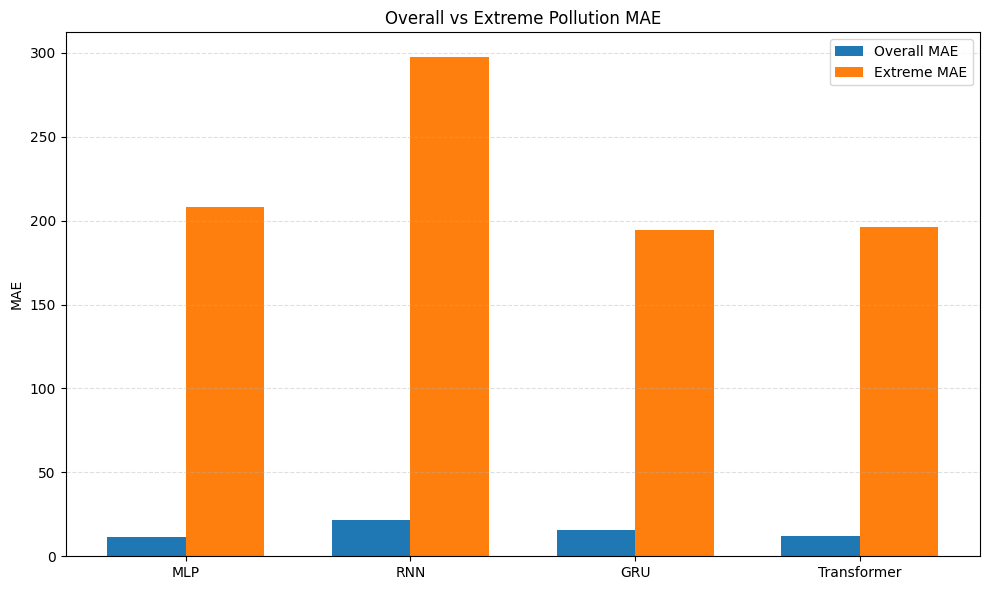

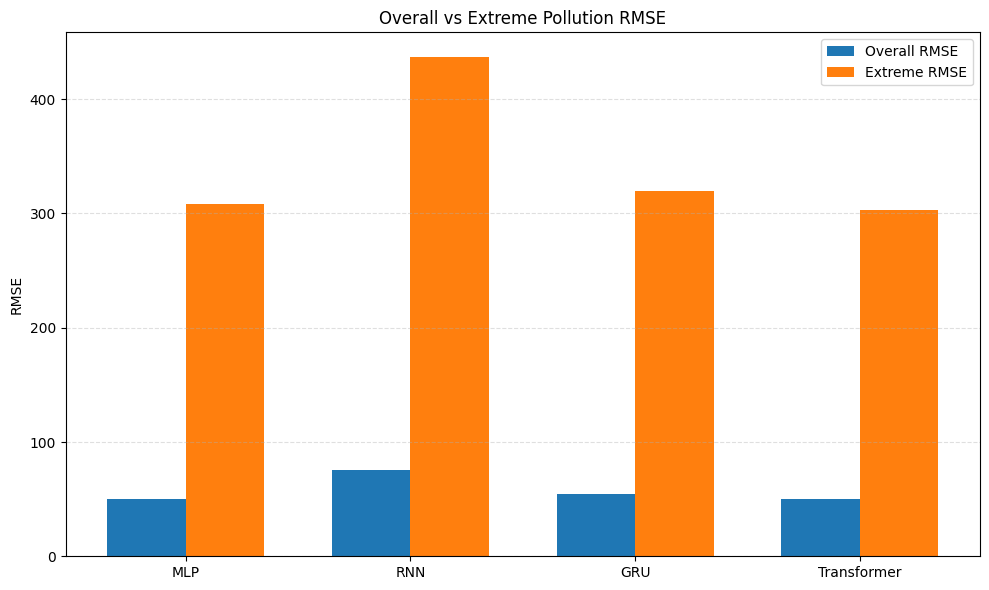

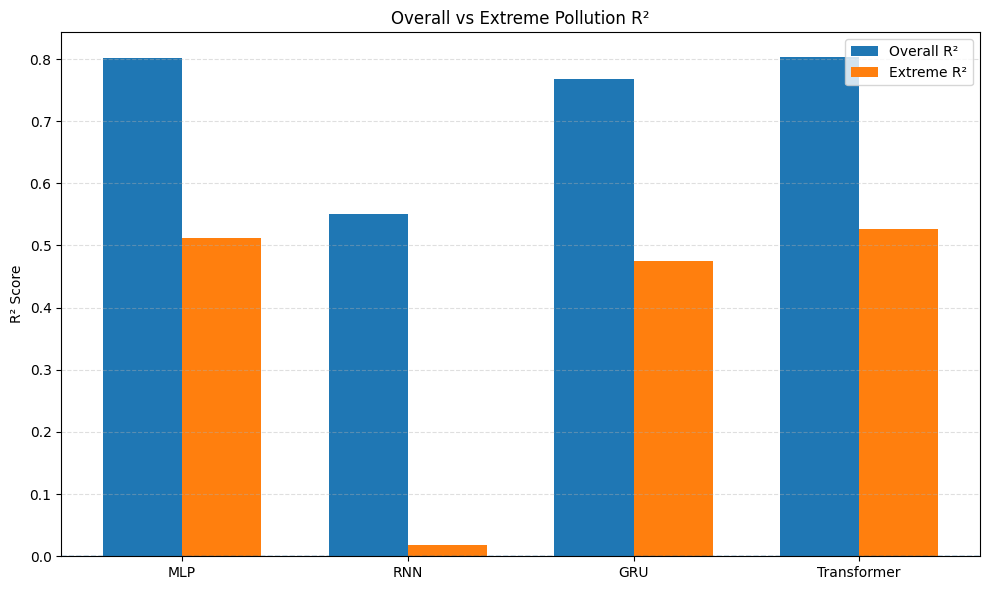


All three visualizations generated successfully.
 COMPLETED SUCCESSFULLY.


In [54]:

# ============================================================
#  VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print(" MODEL PERFORMANCE VISUALIZATION")
print("=" * 70)

# Extract model names and performance metrics.
model_names = model_comparison["Model"].tolist()

overall_mae = model_comparison["Overall MAE"].to_numpy()
extreme_mae = model_comparison["Extreme MAE"].to_numpy()

overall_rmse = model_comparison["Overall RMSE"].to_numpy()
extreme_rmse = model_comparison["Extreme RMSE"].to_numpy()

overall_r2 = model_comparison["Overall R2"].to_numpy()
extreme_r2 = model_comparison["Extreme R2"].to_numpy()

x = np.arange(len(model_names))
width = 0.35

# ------------------------------------------------------------
# Plot 1: Overall vs Extreme MAE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    overall_mae,
    width,
    label="Overall MAE"
)

plt.bar(
    x + width / 2,
    extreme_mae,
    width,
    label="Extreme MAE"
)

plt.xticks(x, model_names)
plt.ylabel("MAE")
plt.title("Overall vs Extreme Pollution MAE")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot 2: Overall vs Extreme RMSE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    overall_rmse,
    width,
    label="Overall RMSE"
)

plt.bar(
    x + width / 2,
    extreme_rmse,
    width,
    label="Extreme RMSE"
)

plt.xticks(x, model_names)
plt.ylabel("RMSE")
plt.title("Overall vs Extreme Pollution RMSE")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot 3: Overall vs Extreme R2
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    overall_r2,
    width,
    label="Overall R²"
)

plt.bar(
    x + width / 2,
    extreme_r2,
    width,
    label="Extreme R²"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xticks(x, model_names)
plt.ylabel("R² Score")
plt.title("Overall vs Extreme Pollution R²")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("\nAll three visualizations generated successfully.")
print(" COMPLETED SUCCESSFULLY.")


#  Final Conclusion

## Research Objective

This study investigated whether Deep Learning models maintain reliable prediction performance during extreme air pollution episodes in Indian cities. Four architectures—Multilayer Perceptron (MLP), Simple Recurrent Neural Network (RNN), Gated Recurrent Unit (GRU), and Transformer—were evaluated using a common parameter budget of **76,601 parameters per model**.

The evaluation considered both overall test performance and performance on extreme pollution samples, defined as **US_AQI ≥ 201**.

## Key Findings

### 1. Overall Prediction Performance

The MLP achieved the lowest overall Mean Absolute Error (MAE) of **11.6993**. The Transformer achieved the highest overall R² score of **0.8028**, with an overall MAE of **12.2016**. The GRU achieved an overall MAE of **15.4666**, while the RNN recorded an MAE of **21.6034**.

### 2. Performance During Extreme Pollution

Extreme pollution samples represented approximately **2.57% of the test set**, corresponding to 4,324 observations out of 168,432 test samples.

During these episodes, the GRU achieved the lowest extreme MAE of **194.6090**, followed by the Transformer at **196.4280** and the MLP at **208.2278**. The RNN recorded the highest extreme MAE of **297.3423**.

### 3. Model Robustness

The results show that model performance depends on the evaluation conditions. The MLP performed best by overall MAE, whereas the GRU performed best by extreme MAE. The Transformer achieved the highest overall and extreme R² scores among the four models in this experiment.

These findings demonstrate why overall test metrics alone are insufficient for evaluating air-quality prediction systems intended for extreme pollution conditions.

### 4. Limitations

Extreme pollution observations formed a relatively small proportion of the test set. Therefore, the findings should be interpreted with this class imbalance in mind. Further evaluation across cities, pollution episodes, seasons, and alternative temporal splits would help establish the generalisability of the results.

Although all four models were designed with equal parameter counts, equal parameter budgets do not guarantee identical learning capacity, optimisation behaviour, or computational cost.

## Final Conclusion

This experiment indicates that Deep Learning model reliability should be evaluated separately during extreme pollution episodes rather than inferred solely from overall test performance. The MLP was strongest by overall MAE, while the GRU produced the lowest extreme MAE in this experiment. The Transformer also demonstrated competitive performance across both evaluation settings.

Consequently, the most suitable architecture depends on the operational objective and the relative importance of average prediction accuracy versus performance during extreme pollution. Future work should investigate episode-based validation, city-wise generalisation, uncertainty estimation, and methods designed to improve predictions under rare, high-pollution conditions.

**Research takeaway:** Reliable air-quality prediction requires explicit evaluation under extreme conditions, because strong average performance does not necessarily imply equally strong performance during severe pollution events.